# Discretization and Binning (Data Mapping & Transformation)

### 📌 Project Summary
Is notebook ka maqsad Pandas library ke do main functions (`map()` aur `replace()`) aur `pd.cut()` (Binning) ko seekhna hai:
1. **`.map()`:** Ek column ki values ko dictionary ke mutabiq tabdeel karna.
2. **`.replace()`:** Kisi makhsoos value ko permanently badalna (jaise 'pak' ko 'pakistan').
3. **`pd.cut()`:** Numbers ko groups (Low, Medium, High) me taqseem karna.

In [5]:
import pandas as pd

# 1. Food ka DataFrame banana
df_food = pd.DataFrame({'food': ['abc','bacon', 'pulled pork', 'bacon', 'pastrami', 'honey ham']})

# 2. Mapping dictionary
meat_to_animal = {
    'bacon': 'pig',
    'pulled pork': 'pig',
    'pastrami': 'cow',
    'honey ham': 'pig'
}

# 3. Column badalna (.str.lower() taake choti badi ABC ka farq na paray)
df_food['animal'] = df_food['food'].str.lower().map(meat_to_animal)

# Output dekhna
df_food

,food,animal
0,abc,NaN
1,bacon,pig
2,pulled pork,pig
3,bacon,pig
4,pastrami,cow
5,honey ham,pig


In [6]:
# (Code Cell) — Dataset 2: Event Codes & Cost Binning Ek aur naya Code cell banayein aur is me yeh code paste karein:
import pandas as pd

# 1. Events aur Cost ka basic DataFrame banana
df_event = pd.DataFrame({
    'Date': ['10/2/2011', '11/2/2011', '12/2/2011', '13/2/2011'],
    'Event': ['Music', 'Poetry', 'Theatre', 'Comedy'],
    'Cost': [10000, 5000, 15000, 2000]
})

# Output check karein
df_event

,Date,Event,Cost
0,10/2/2011,Music,10000
1,11/2/2011,Poetry,5000
2,12/2/2011,Theatre,15000
3,13/2/2011,Comedy,2000


In [7]:
# Is cell me hum Events ke naamo ko short codes ('M', 'P', 'T', 'C') me badlein ge.
# 2. Event short codes ki dictionary banana
event_dict = {'Music': 'M', 'Poetry': 'P', 'Theatre': 'T', 'Comedy': 'C'}

# 3. Event column ko map kar ke naya column 'E' banana
df_event['E'] = df_event['Event'].map(event_dict)

# Output check karein (Ab 'E' ka column sath nazar aaye ga)
df_event

,Date,Event,Cost,E
0,10/2/2011,Music,10000,M
1,11/2/2011,Poetry,5000,P
2,12/2/2011,Theatre,15000,T
3,13/2/2011,Comedy,2000,C


In [8]:
# Is cell me hum numeric 'Cost' ko categories (Low, Medium, High) me taqseem karein ge.
# 4. Bins (Ranges) aur unke Labels set karna
bins = [0, 3000, 10000, 20000]
labels = ['Low', 'Medium', 'High']

# 5. pd.cut() use kar ke binning apply karna
df_event['Cost_Category'] = pd.cut(df_event['Cost'], bins=bins, labels=labels)

# Output check karein (Ab categories ka alag column ban chuka hoga)
df_event

,Date,Event,Cost,E,Cost_Category
0,10/2/2011,Music,10000,M,Medium
1,11/2/2011,Poetry,5000,P,Medium
2,12/2/2011,Theatre,15000,T,High
3,13/2/2011,Comedy,2000,C,Low


In [9]:
# Yahan se naya Employee wala data set shoru ho raha hai.
# 1. Employees ka chota aur saaf DataFrame banana
emp = pd.DataFrame({
    'emp_name': ['nasir','asad','fahan' ,'noman', 'ali', 'ahmer'],
    'country': ['pak', 'pak', 'ind', 'usa', 'iran', 'iraq'],
    'age': [23, 34.5, 40, 54.2, 20, 30]
})

# Output check karein
emp

,emp_name,country,age
0,nasir,pak,23.0
1,asad,pak,34.5
2,fahan,ind,40.0
3,noman,usa,54.2
4,ali,iran,20.0
5,ahmer,iraq,30.0


In [10]:
# Is cell me hum country ko dekh kar unke shehron (Capitals) ka naya column banayein ge.
# 2. Country se Capital ki dictionary
country_capital = {
    'pak': 'islamabad', 'ind': 'delhi', 'usa': 'washington',
    'iran': 'tehran', 'iraq': 'baghdad'
}

# 3. .map() function se capital column add karna
emp['capital'] = emp['country'].map(country_capital)

# Output check karein
emp

,emp_name,country,age,capital
0,nasir,pak,23.0,islamabad
1,asad,pak,34.5,islamabad
2,fahan,ind,40.0,delhi
3,noman,usa,54.2,washington
4,ali,iran,20.0,tehran
5,ahmer,iraq,30.0,baghdad


In [11]:
# Is aakhri cell me hum 'pak' ko mita kar poora 'pakistan' likhein ge.
# 4. .replace() use kar ke 'pak' ko 'pakistan' banana
emp['country'].replace('pak', 'pakistan', inplace=True)

# Final Output check karein
emp

C:\Users\Adil\AppData\Local\Temp\ipykernel_10520\2364232.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  emp['country'].replace('pak', 'pakistan', inplace=True)


,emp_name,country,age,capital
0,nasir,pakistan,23.0,islamabad
1,asad,pakistan,34.5,islamabad
2,fahan,ind,40.0,delhi
3,noman,usa,54.2,washington
4,ali,iran,20.0,tehran
5,ahmer,iraq,30.0,baghdad


In [12]:
# Jo aap str.replace(['p', 'u','i'], ...) se karna chah rahe the, us ka sahi 
# aur short tareeqa yeh hai ke hum .replace() ke andar ek dictionary bana kar de dein:
# 2. 'p' ko 'P', 'u' ko 'U', aur 'i' ko 'I' me badalna
emp['country'] = emp['country'].replace({'p':'P', 'u':'U', 'i':'I'}, regex=True)

# Output check karein (Ab Pakistan, Usa, Iran wagera ke letters capital ho chuke honge)
emp

# Not: Yahan regex=True likhna zaroori hai taake Pandas ko pata chale ke hum ne poora lafze nahi badalna, balkay lafze ke andar se letters badalne hain.

,emp_name,country,age,capital
0,nasir,PakIstan,23.0,islamabad
1,asad,PakIstan,34.5,islamabad
2,fahan,Ind,40.0,delhi
3,noman,Usa,54.2,washington
4,ali,Iran,20.0,tehran
5,ahmer,Iraq,30.0,baghdad


In [13]:
# Aap ke sir ne jo aakhri line di thi jahan 'ahmed', 'ahmer', aur 'asad' ko badalna tha, us ka sahi aur working code yeh hai:
# 3. Names ko list ke zariye badalna
emp['emp_name'] = emp['emp_name'].replace(['ahmed','ahmer', 'asad'], ['hello','hi','bye'])

# Final Output check karein
emp

,emp_name,country,age,capital
0,nasir,PakIstan,23.0,islamabad
1,bye,PakIstan,34.5,islamabad
2,fahan,Ind,40.0,delhi
3,noman,Usa,54.2,washington
4,ali,Iran,20.0,tehran
5,hi,Iraq,30.0,baghdad


In [15]:

import pandas as pd

# Data banana aur map karna
df = pd.DataFrame({'food': ['abc','bacon', 'pulled pork', 'pastrami', 'honey ham']})
meat_to_animal = {'bacon': 'pig', 'pulled pork': 'pig', 'pastrami': 'cow', 'honey ham': 'pig'}

df['animal'] = df['food'].str.lower().map(meat_to_animal)
df

,food,animal
0,abc,NaN
1,bacon,pig
2,pulled pork,pig
3,pastrami,cow
4,honey ham,pig


In [16]:
# Event data banana aur code map karna
df = pd.DataFrame({'Date': ['10/2/2011', '11/2/2011', '12/2/2011', '13/2/2011'],
                   'Event': ['Music', 'Poetry', 'Theatre', 'Comedy'],
                   'Cost': [10000, 5000, 15000, 2000]})

d = {'Music': 'M', 'Poetry': 'P', 'Theatre': 'T', 'Comedy': 'C'}
df['E'] = df['Event'].map(d)
df

,Date,Event,Cost,E
0,10/2/2011,Music,10000,M
1,11/2/2011,Poetry,5000,P
2,12/2/2011,Theatre,15000,T
3,13/2/2011,Comedy,2000,C


# Discretization and Binning

### 📌 Summary
* **Continuous Data:** Jo numbers points/decimals me hon (jaise Distance: 10.3).
* **Discrete Data:** Jo mukammal numbers hon (jaise Rooms: 3).
* **Binning:** Numbers ko groups (Low, Medium, High) me badalna.

In [17]:
# Employee data banana, map karna aur replace karna
emp = pd.DataFrame({'emp_name':['nasir','asad','fahan' ,'noman'],
                    'country':['pak', 'pak', 'ind', 'usa'],
                    'age':[23, 34.5, 40, 54.2]})

country_capital = {'pak':'islamabad', 'ind':'delhi','usa':'washington'}
emp['capital'] = emp.country.map(country_capital)

# Sahi tareeqe se replace karna (bina error ke)
emp['country'] = emp['country'].replace('pak', 'pakistan')
emp['country'] = emp['country'].replace({'p':'P', 'u':'U', 'i':'I'}, regex=True)
emp['emp_name'] = emp['emp_name'].replace(['ahmed','ahmer', 'asad'], ['hello','hi','bye'])
emp

,emp_name,country,age,capital
0,nasir,PakIstan,23.0,islamabad
1,bye,PakIstan,34.5,islamabad
2,fahan,Ind,40.0,delhi
3,noman,Usa,54.2,washington


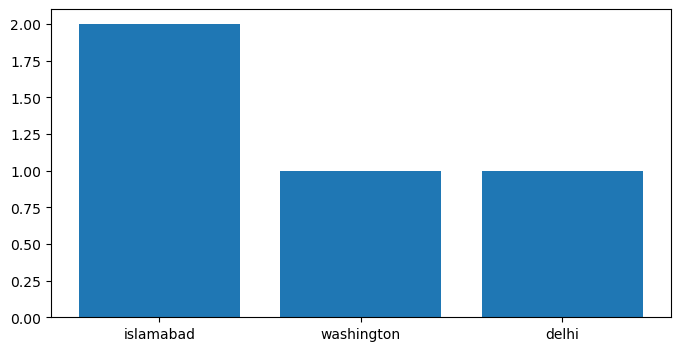

In [19]:
import random
import matplotlib.pyplot as plt

# Index badalna aur shuffle karna
emp.index = [random.randint(1000000,9999999) for i in range(len(emp))]
emp = emp.sample(len(emp)).reset_index(drop=True)

# Graph banana
freq = emp.capital.value_counts().values
country = emp.capital.value_counts().index

plt.figure(figsize=(8,4))
plt.bar(x=country, height=freq)
plt.show()

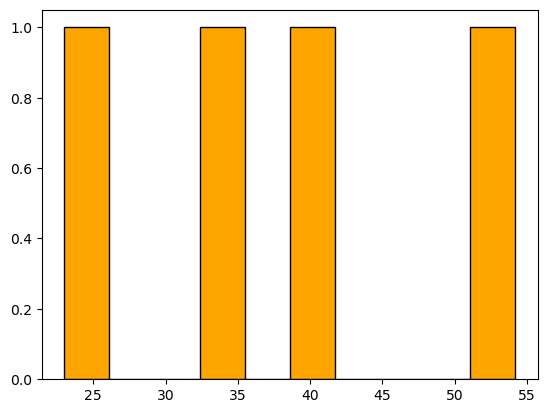

In [20]:
# Is cell se aap ki 'age' column ka histogram (distribution graph) banega.
import matplotlib.pyplot as plt

# Age column ka histogram graph banana
plt.hist(x=emp.age, color='orange', edgecolor='black')
plt.show()

In [21]:
# Is cell me hum age ko ranges me torr kar 'Nojawan', 'jawan', aur 'budha' ki categories banayein ge.
# Age ko categories me cut karna: 19-35 (Nojawan), 36-50 (jawan), 51-65 (budha)
emp['age_category'] = pd.cut(emp.age, bins=[19, 35, 50, 65], labels=['Nojawan', 'jawan', 'budha'])

# Output check karein (Naya column table me add ho jayega)
emp

,emp_name,country,age,capital,age_category
0,noman,Usa,54.2,washington,budha
1,bye,PakIstan,34.5,islamabad,Nojawan
2,nasir,PakIstan,23.0,islamabad,Nojawan
3,fahan,Ind,40.0,delhi,jawan


In [22]:
# Har category ki total ginti (tadaad) nikalna
emp.age_category.value_counts()

age_category
Nojawan    2
jawan      1
budha      1
Name: count, dtype: int64

# 📌 Final Project Summary: Hum Ne Is Data Set Me Kya Kya Kam Kiya?

Is poori notebook me hum ne raw data par kaam kiya, us me tabdeeliyaan (changes) kein, aur naye columns banaye. Mukammal kaam ki tafseel neache di gayi hai:

---

### 1. 🍔 Dataset 1: Food To Animal Mapping
* **Hum ne kya kiya:** Hum ne `food` column ke naamo ko dekha aur `.map()` function ke zariye un ke mutabiqa janwar (`animal`) ka naya column banaya.
* **Key Change:** Hum ne `.str.lower()` ka istemal kiya taake choti ya badi ABC (case-sensitivity) ki wajah se code me error na aaye.

### 2. 🎭 Dataset 2: Event Short Codes & Cost Binning
* **Hum ne kya kiya:** Hum ne `Event` column ke baday naamo (Music, Poetry) ko chote single-letter codes (`M`, `P`, `T`, `C`) me map kiya.
* **Binning:** Hum ne event ki `Cost` (fees) ko `pd.cut()` ke zariye groups me takseem kar ke yeh check kiya ke konsa event sasta hai aur konsa mehanga (Low, Medium, High).

### 3. 👥 Dataset 3: Employee Data & Text Cleaning (Sab se Zeada Changes)
Is data set me hum ne sab se zeada kaam aur tabdeeliyaan kein:
* **Capital City Mapping:** Hum ne employee ki `country` (mulk) dekh kar us ke samne us ke `capital` (shehar) ka naya column banaya.
* **Permanent Replace:** Hum ne error aur warning ke bagair `pak` ko mita kar poora `pakistan` likha.
* **Text Transformation:** Hum ne data ke andar makhsoos aksharo (letters) jaise `p`, `u`, `i` ko capital letters (`P`, `U`, `I`) me badla.
* **Multiple Names Replacement:** Hum ne aik hi line me ek sath multiple naamo ko badal kar `hello`, `hi`, `bye` kiya.

### 4. 🎲 Indexing, Sampling, and Shuffling
* **Random Index:** Hum ne employees ke normal index (0, 1, 2) ko mita kar 7-digits ke random numbers lagaye.
* **Data Shuffling:** Hum ne `.sample()` ka istemal kar ke data ko upar-neeche (shuffle) kiya aur phir `.reset_index(drop=True)` se index ko dobara saaf kar ke 0 se shoru kiya.

### 5. 📊 Data Visualization & Age Binning (Asal Topic)
* **Bar Chart:** Hum ne Matplotlib library use kar ke ek graph banaya jo dikhata hai ke kaunsa shehar data me kitni baar aaya hai.
* **Histogram:** Hum ne employees ki `age` (umar) ka distribution graph banaya.
* **Age Binning (Discretization):** Hum ne continuous age (numbers) ko discrete categories me badla. Hum ne age ke mutabiq logon ko 3 categories me baanta: **Nojawan** (19-35), **jawan** (36-50), aur **budha** (51-65).
* **Value Counts:** Aakhri step me hum ne check kiya ke hamare paas total kitne Nojawan, jawan aur budhay log maujood hain.

---
**💡 Conclusion:** Hum ne seekha ke kaise ek rough data ko saaf kar ke, us par mapping apply kar ke, aur numbers ko bins (groups) me torr kar graph ke zariye analyze kiya jata hai!